In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from os import path
from scipy import stats
from tqdm.notebook import tqdm

import matplotlib

from pymodulon.io import load_json_model
from pymodulon.plotting import *

In [2]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['svg.fonttype'] = 'none'
matplotlib.rcParams['font.sans-serif'] = 'Arial'
matplotlib.rcParams['font.family'] = 'sans-serif'
sns.set_style('ticks')
matplotlib.rcParams['text.color'] = '#000000'
matplotlib.rcParams['axes.labelcolor'] = '#000000'
matplotlib.rcParams['xtick.color'] = '#000000'
matplotlib.rcParams['ytick.color'] = '#000000'

# Import Data

In [3]:
# import the ICA Data Structure
ica_data = load_json_model('data/modulome_sc.json')

In [4]:
# import TPM data for new samples for downstream activity calculations
logTPM_file = path.join('data/new_data/test_log_tpm.csv') # Enter log-TPM filename here
counts_file = path.join('data/new_data/test_counts.csv') # enter counts file for new data here
metadata_file = path.join("data/new_data/test_metadata.csv") # Enter curated metadata filename here

In [5]:
DF_log_tpm = pd.read_csv(logTPM_file,index_col=[0], sep=',').fillna(0)
DF_counts = pd.read_csv(counts_file, index_col=0, sep = ',').fillna(0)
DF_metadata = pd.read_csv(metadata_file,index_col=0, sep=',')

In [6]:
DF_log_tpm.index = [x[5:] for x in DF_log_tpm.index]
DF_log_tpm = DF_log_tpm.loc[ica_data.M.index]

DF_counts.index = [x[5:] for x in DF_counts.index]
DF_counts = DF_counts.loc[ica_data.M.index]

# Centering of data for downstream activity calculations

In [7]:
# -----------------------------
# ORIGINAL TRAINING DATA
# genes x samples
# -----------------------------
counts_train = pd.read_csv('data/ica_counts_data/train_counts.csv',index_col=0).fillna(0)
counts_train.index =  [x[5:] for x in counts_train.index]

# Compute geometric means from ORIGINAL data only
geom_means = np.exp(
    np.log(counts_train.replace(0, np.nan)).mean(axis=1)
)

# -----------------------------
# FULL DATASET
# genes x expanded samples
# -----------------------------
counts_full = DF_counts

# Compute ratios
ratios = counts_full.div(geom_means, axis=0)

# Ignore inf/nan from zeros
ratios = ratios.replace([np.inf, -np.inf], np.nan)

# Median-of-ratios size factors
size_factors_full = ratios.median(axis=0)

# Normalize
normalized_full = counts_full.div(size_factors_full, axis=1)

# Log transform
log_normalized_full = np.log2(normalized_full + 1)

In [8]:
# normalize log tpm data
project_exprs = []
for name,group in DF_metadata.groupby('project'):
    
    # Get reference condition
    ref_cond = group.reference_condition.iloc[0]
    
    # Get reference condition sample ids
    ref_samples = group[group.condition == ref_cond].index
    
    # Get reference condition expression
    ref_expr = log_normalized_full[ref_samples].mean(axis=1)
    
    # Subtract reference expression from project
    project_exprs.append(log_normalized_full[group.index].sub(ref_expr,axis=0))

DF_log_counts_norm = pd.concat(project_exprs,axis=1)

# Infer Activities

In [9]:
from pymodulon.util import infer_activities
# Run inference with properly aligned data
activities = infer_activities(ica_data, DF_log_counts_norm)

/home/jtburrow/miniconda3/envs/modulome_sc/lib/python3.7/site-packages/pymodulon/util.py:327: FutureWarning: Index.__and__ operating as a set operation is deprecated, in the future this will be a logical operation matching Series.__and__.  Use index.intersection(other) instead
  shared_genes = ica_data.M.index & data.index


# Testing Performance on Existing Samples

In [10]:
baseline = DF_log_counts_norm

# Base error (variance of original centered data)
base_err = np.linalg.norm(baseline) ** 2
 
# Reconstruction: M @ A
MA = ica_data.M.values @ activities.values

# Reconstruction error
sa_err = np.linalg.norm(MA - baseline) ** 2

# Variance explained
var_explained = np.clip(1 - sa_err / base_err, 0, 1)
var_explained

0.6929161885815555

# Plotting and Analysis of the Inferred Activities

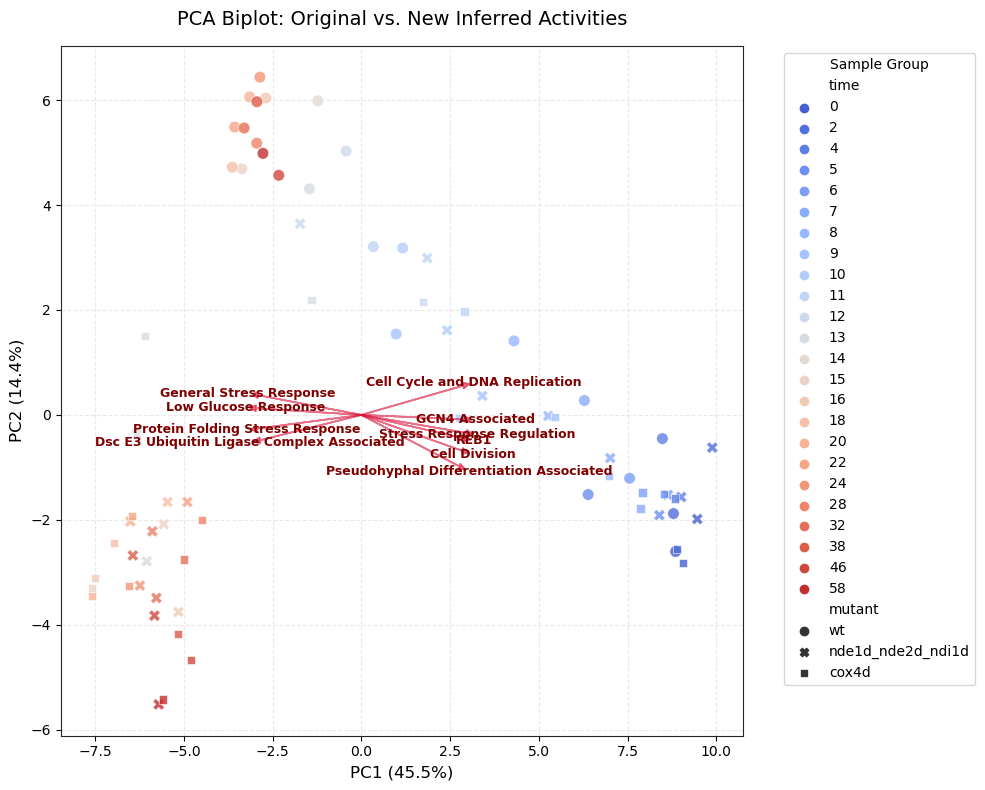

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Standardize and run PCA on the inferred activities
scaler = StandardScaler()
activities_scaled = scaler.fit_transform(activities.T)

pca = PCA(n_components=2)
pca_scores = pca.fit_transform(activities_scaled)

# 2. Create the Scores DataFrame
df_scores = pd.DataFrame(
    pca_scores, columns=["PC1", "PC2"], index=activities.columns
)

# 3. Create a column to identify the source of the sample
# We check if the sample name exists in the original ica_data.A columns
original_samples = set(ica_data.A.columns)
df_scores["condition"] = [DF_metadata.loc[sample, 'condition'] for sample in df_scores.index]
df_scores["mutant"] = df_scores.condition.apply(lambda x: x.rsplit('_', maxsplit=1)[0])
df_scores["time"] = df_scores.condition.apply(lambda x: x.rsplit('_', maxsplit=1)[1][1:])



# 4. Create the Loadings DataFrame (ICs / i-modulons)
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
df_loadings = pd.DataFrame(
    loadings, columns=["PC1", "PC2"], index=activities.index
)

# 5. Plotting
fig, ax = plt.subplots(figsize=(10, 8))

# Scatter plot: Color points by 'Sample_Source'
# We use a distinct palette to easily tell them apart
sns.scatterplot(
    data=df_scores,
    x="PC1",
    y="PC2",
    hue="time",
    style='mutant',
    palette='coolwarm',
    alpha=0.8,
    s=70,
    edgecolor="w",
    linewidth=0.5,
    ax=ax,
)

# 6. Overlay the arrows for the top N i-modulons
arrow_expansion = 3.0
top_n_arrows = 10
important_ics = (df_loadings["PC1"] ** 2 + df_loadings["PC2"] ** 2).nlargest(
    top_n_arrows
).index

for imodulon in important_ics:
    x = df_loadings.loc[imodulon, "PC1"] * arrow_expansion
    y = df_loadings.loc[imodulon, "PC2"] * arrow_expansion

    # Draw arrow
    ax.arrow(
        0,
        0,
        x,
        y,
        color="crimson",
        alpha=0.6,
        head_width=0.04 * arrow_expansion,
        linewidth=1.2,
    )
    # Label arrow
    ax.text(
        x * 1.1,
        y * 1.1,
        imodulon,
        color="maroon",
        ha="center",
        va="center",
        fontsize=9,
        weight="bold",
    )

# Formatting
pc1_var = pca.explained_variance_ratio_[0] * 100
pc2_var = pca.explained_variance_ratio_[1] * 100
ax.set_xlabel(f"PC1 ({pc1_var:.1f}%)", fontsize=12)
ax.set_ylabel(f"PC2 ({pc2_var:.1f}%)", fontsize=12)
ax.set_title(
    "PCA Biplot: Original vs. New Inferred Activities", fontsize=14, pad=15
)
ax.grid(True, linestyle="--", alpha=0.4)

# Clean up legend placement
ax.legend(title="Sample Group", loc="best", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

/home/jtburrow/miniconda3/envs/modulome_sc/lib/python3.7/site-packages/scipy/stats/stats.py:4023: PearsonRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(PearsonRConstantInputWarning())


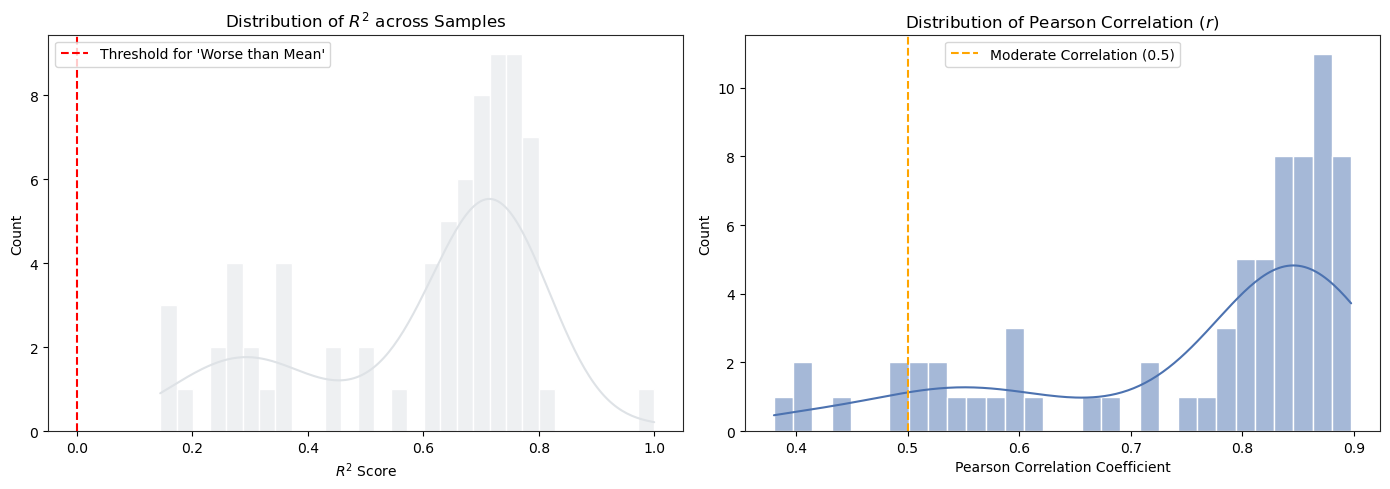

Total Samples evaluated: 72
Samples with positive R2: 72 (100.0%)
Samples with Pearson r > 0.5: 65 (90.3%)


In [12]:
from scipy.stats import pearsonr, spearmanr

# 1. Reconstruct the matrix
X_actual = DF_log_counts_norm.loc[ica_data.M.index, [x for x in activities.columns if x not in ica_data.A.columns]]
X_recon = pd.DataFrame(
    np.dot(ica_data.M.values, activities[[x for x in activities.columns if x not in ica_data.A.columns]].values),
    index=X_actual.index,
    columns=X_actual.columns,
)

# 2. Calculate both R2 and Pearson Correlation for every sample
performance_metrics = []
for sample in [x for x in activities.columns if x not in ica_data.A.columns]:
    # Calculate R2 using the original global-mean centered data you ran
    r2 = r2_score(X_actual[sample], X_recon[sample])
    # Calculate Pearson correlation
    corr, _ = pearsonr(X_actual[sample], X_recon[sample])

    performance_metrics.append(
        {"Sample": sample, "R2": r2, "Pearson_r": corr}
    )

df_perf = pd.DataFrame(performance_metrics)

# 3. Plotting the Global Audit
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Distribution of R2 values
sns.histplot(df_perf["R2"], bins=30, kde=True, ax=axes[0], color="#DEe2e6")
axes[0].axvline(
    0, color="red", linestyle="--", label="Threshold for 'Worse than Mean'"
)
axes[0].set_title("Distribution of $R^2$ across Samples")
axes[0].set_xlabel("$R^2$ Score")
axes[0].legend()

# Plot 2: Distribution of Pearson Correlation
sns.histplot(df_perf["Pearson_r"], bins=30, kde=True, ax=axes[1], color="#4C72B0")
axes[1].axvline(
    0.5, color="orange", linestyle="--", label="Moderate Correlation (0.5)"
)
axes[1].set_title("Distribution of Pearson Correlation ($r$)")
axes[1].set_xlabel("Pearson Correlation Coefficient")
axes[1].legend()

plt.tight_layout()
plt.show()

# Print Global Summary statistics
print(f"Total Samples evaluated: {len(df_perf)}")
print(
    f"Samples with positive R2: {sum(df_perf['R2'] > 0)} ({sum(df_perf['R2'] > 0)/len(df_perf)*100:.1f}%)"
)
print(
    f"Samples with Pearson r > 0.5: {sum(df_perf['Pearson_r'] > 0.5)} ({sum(df_perf['Pearson_r'] > 0.5)/len(df_perf)*100:.1f}%)"
)

## Output Activities

In [13]:
activities.to_csv('output_activities.csv')